⏳ Loading spatial grid and isolating natural tiles...
⏳ Computing positive landward migration shift (excluding ['S19E063']) & extracting landward area time-series...
⏳ Compiling map layout and regional insets...


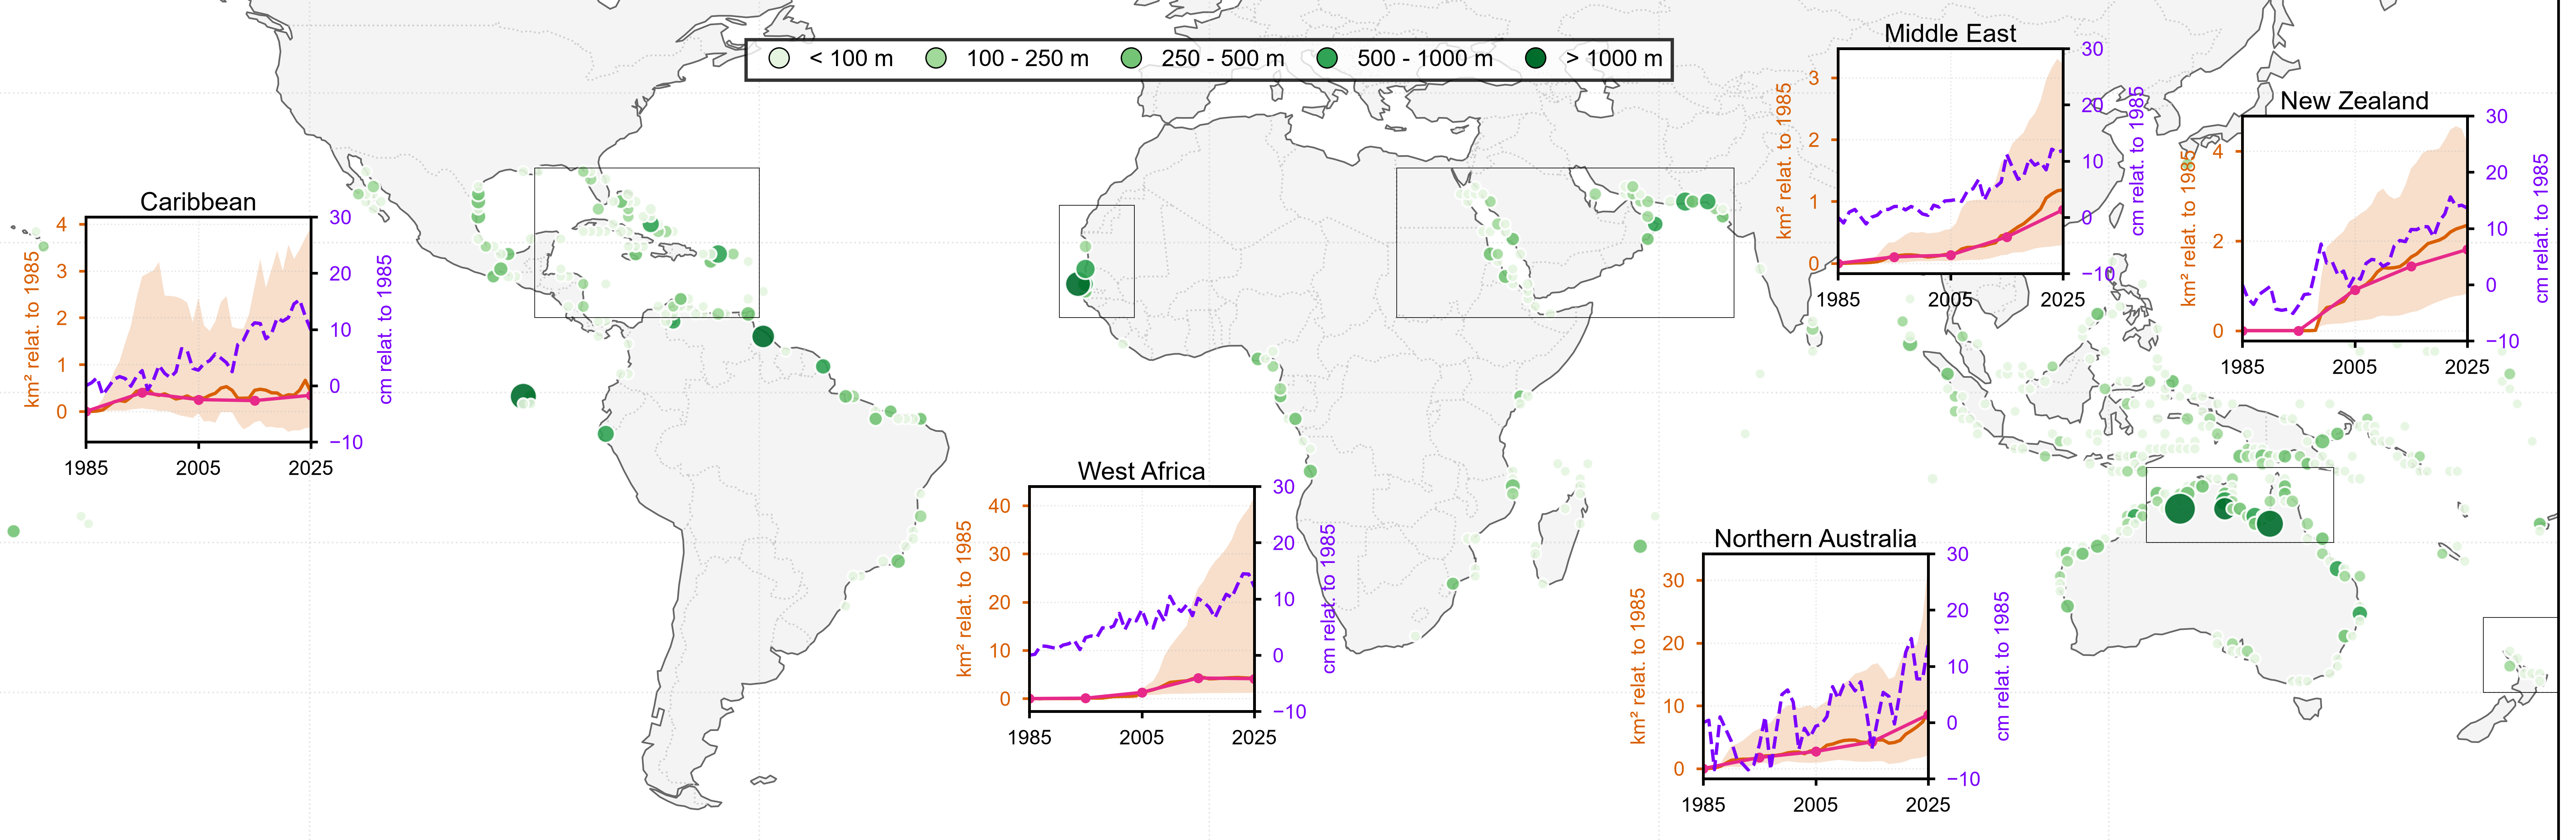

🎉 Figure 2 successfully saved at: D:\MANGROVES\Research_Article_Clean\Figure2\figure2.tif


In [18]:
"""
================================================================================
SCRIPT NAME: Figure 2

AUTHOR: R. Walcker, CRBE
================================================================================
"""

from pathlib import Path
import warnings
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import Point

warnings.filterwarnings("ignore")

# ==============================================================================
# 0. CONFIGURATION & TYPOGRAPHY STANDARDS
# ==============================================================================
OUT_DIR = Path(r"D:\MANGROVES\Research_Article_Clean\Figure2")
OUT_DIR.mkdir(parents=True, exist_ok=True)

YEARLY_STATS_DIR = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\Distance_CSVs")
SHP_VAL_PATH = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\gmwv4_mask_anthropogenic_validation.shp")
CSV_MSL_PATH = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\ecmwf_msl_annual_1deg_tiles.csv")
CSV_MANGROVES = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\gmwv4_surfaces_annual_1deg_tiles.csv")

MAX_DIST_LIMIT = 20000
PIXEL_AREA_KM2 = (29.869 ** 2) / 1e6

# Manual exclusions (e.g., erroneous water baseline raster)
EXCLUDED_TILES = {"S19E063"}
excluded_upper = {t.strip().upper() for t in EXCLUDED_TILES}

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "axes.linewidth": 0.8,
    "font.size": 8.0,
    "axes.labelsize": 8.0,
    "axes.titlesize": 9.0,
    "xtick.labelsize": 7.0,
    "ytick.labelsize": 7.0,
})

# ==============================================================================
# 1. STUDY REGIONS DEFINITION
# ==============================================================================
study_regions = [
    {"title": "Caribbean", "lat_range": (10.0, 30.0), "lon_range": (-90.0, -60.0), "inset_center": (-150.0, 20.0)},
    {"title": "West Africa", "lat_range": (10.0, 25.0), "lon_range": (-20.0, -10.0), "inset_center": (-10.0, -20.0)},
    {"title": "Middle East", "lat_range": (10.0, 30.0), "lon_range": (25.0, 70.0), "inset_center": (110.0, 45.0)},
    {"title": "Northern Australia", "lat_range": (-20.0, -10.0), "lon_range": (125.0, 150.0), "inset_center": (90.0, -30.0)},
    {"title": "New Zealand", "lat_range": (-40.0, -30.0), "lon_range": (170.0, 180.0), "inset_center": (170.0, 35.0)}
]

# ==============================================================================
# 2. DATA LOADING & ISOLATING NATURAL TILES
# ==============================================================================
print("⏳ Loading spatial grid and isolating natural tiles...")

gdf_val = gpd.read_file(SHP_VAL_PATH)
tile_col_val = "clean_id" if "clean_id" in gdf_val.columns else "tile_id"
gdf_val["tile_id_clean"] = gdf_val[tile_col_val].astype(str).str.strip().str.upper()

if gdf_val.crs is not None and gdf_val.crs.to_string() != "EPSG:4326":
    gdf_val = gdf_val.to_crs(epsg=4326)

manual_mask_dict = dict(zip(gdf_val["tile_id_clean"], gdf_val["mask_artif"]))
nat_tiles_set = {
    tid for tid, artif in manual_mask_dict.items()
    if artif == 0 and tid not in excluded_upper
}

df_mng_raw = pd.read_csv(CSV_MANGROVES, sep=";")
df_mng_raw["tile_id"] = df_mng_raw["tile_id"].astype(str).str.strip().str.upper()
df_mng_raw["year"] = df_mng_raw["year"].astype(int)

df_msl_raw = pd.read_csv(CSV_MSL_PATH, sep=";")
if len(df_msl_raw.columns) == 1:
    df_msl_raw = pd.read_csv(CSV_MSL_PATH, sep=",")

df_msl_raw["tile_id"] = df_msl_raw["tile_id"].astype(str).str.strip().str.upper()
df_msl_raw["year"] = df_msl_raw["year"].astype(int)

coords_df = df_msl_raw[["tile_id", "center_lon", "center_lat"]].drop_duplicates(subset=["tile_id"]).set_index("tile_id")
coords_dict = coords_df.to_dict(orient="index")

df_msl_data = df_msl_raw.pivot(index="year", columns="tile_id", values="SSH_m")
df_msl_data.index = df_msl_data.index.astype(int)
df_msl_data.sort_index(ascending=True, inplace=True)
df_msl_data.columns = df_msl_data.columns.astype(str).str.strip().str.upper()

df_mng_nat = df_mng_raw[df_mng_raw["tile_id"].isin(nat_tiles_set)].copy()
pivot_mng = df_mng_nat.pivot(index="year", columns="tile_id", values="area_km2")

common_nat_tiles = pivot_mng.columns.intersection(df_msl_data.columns)
pivot_mng = pivot_mng[common_nat_tiles]
df_msl_data = df_msl_data[common_nat_tiles]

valid_tiles_results = []
landward_series_dict = {}

print(f"⏳ Computing positive landward migration shift (excluding {sorted(excluded_upper)}) & extracting landward area time-series...")
for tile_id in sorted(nat_tiles_set):
    if tile_id in excluded_upper:
        continue

    csv_path = YEARLY_STATS_DIR / f"mangrove_distances_yearly_{tile_id}.csv"
    if not csv_path.exists():
        continue
        
    try:
        df_z = pd.read_csv(csv_path)
        if df_z.empty or "year" not in df_z.columns or "Dist_to_sea" not in df_z.columns:
            continue
            
        yearly_maxs = {}
        yr_landward_areas = {}
        for yr in df_z["year"].unique():
            dvals = df_z.loc[(df_z["year"] == yr) & (df_z["Dist_to_sea"].notna()), "Dist_to_sea"].astype(float).values
            dvals_filtered = dvals[(dvals >= 0) & (dvals <= MAX_DIST_LIMIT)]
            if len(dvals_filtered) > 0:
                yearly_maxs[yr] = dvals_filtered.max()
            
            # Landward pixels (Dist_to_sea > 0)
            d_sea_subset = df_z.loc[(df_z["year"] == yr) & (df_z["Dist_to_sea"] > 0) & (df_z["Dist_to_sea"] <= MAX_DIST_LIMIT), "Dist_to_sea"].dropna()
            yr_landward_areas[int(yr)] = len(d_sea_subset) * PIXEL_AREA_KM2
                
        if 1985 in yearly_maxs and 2025 in yearly_maxs:
            cumul_shift = yearly_maxs[2025] - yearly_maxs[1985]
            if cumul_shift > 0:
                if tile_id in coords_dict:
                    valid_tiles_results.append({
                        "tile_id": tile_id,
                        "center_lon": coords_dict[tile_id]["center_lon"],
                        "center_lat": coords_dict[tile_id]["center_lat"],
                        "cumulative_shift": cumul_shift
                    })
                    if len(yr_landward_areas) > 0:
                        landward_series_dict[tile_id] = pd.Series(yr_landward_areas)
    except Exception:
        continue

df_exp = pd.DataFrame(valid_tiles_results)
df_landward_pivot = pd.DataFrame(landward_series_dict).sort_index()

# ==============================================================================
# 3. STATISTICAL AGGREGATION & EXPORT (.GPKG)
# ==============================================================================
if not df_exp.empty:
    gdf_export = gpd.GeoDataFrame(
        df_exp[["tile_id"]].copy(),
        geometry=[Point(xy) for xy in zip(df_exp["center_lon"], df_exp["center_lat"])],
        crs="EPSG:4326"
    )
    gdf_export["1985_2025_migration_m"] = df_exp["cumulative_shift"].values
    output_gpkg_path = OUT_DIR / "mangrove_positive_migration_1985_2025.gpkg"
    gdf_export.to_file(output_gpkg_path, driver="GPKG")

mean_shift = df_exp["cumulative_shift"].mean() if not df_exp.empty else 0.0
q25_shift = df_exp["cumulative_shift"].quantile(0.25) if not df_exp.empty else 0.0
q75_shift = df_exp["cumulative_shift"].quantile(0.75) if not df_exp.empty else 0.0
max_shift = df_exp["cumulative_shift"].max() if not df_exp.empty else 0.0

bin_edges = [0, 100, 250, 500, 1000, np.inf]
migration_colors = ["#e5f5e0", "#a1d99b", "#74c476", "#31a354", "#006d2c"]
legend_labels = ["< 100 m", "100 - 250 m", "250 - 500 m", "500 - 1000 m", "> 1000 m"]

if not df_exp.empty:
    df_exp["migration_class"] = pd.cut(
        df_exp["cumulative_shift"], 
        bins=bin_edges, 
        labels=[1, 2, 3, 4, 5], 
        include_lowest=True
    ).astype(int)
    df_exp["color"] = df_exp["migration_class"].map({
        1: migration_colors[0], 
        2: migration_colors[1], 
        3: migration_colors[2], 
        4: migration_colors[3],
        5: migration_colors[4]
    })

# ==============================================================================
# 4. MAPPING & INSETS COMPILATION
# ==============================================================================
print("⏳ Compiling map layout and regional insets...")
fig = plt.figure(figsize=(12.0, 8.5), facecolor="white", dpi=600)
fig.subplots_adjust(top=0.88, bottom=0.05, left=0.08, right=0.92)

ax_map = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax_map.add_feature(cfeature.LAND, facecolor="#f4f4f4", zorder=1)
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor="#666666", zorder=2)
ax_map.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5, edgecolor="#cccccc", zorder=2)

if not df_exp.empty:
    df_map_filtered = df_exp[df_exp["cumulative_shift"] > 0].copy()
    
    if not df_map_filtered.empty:
        min_size, max_size = 10, 90
        shift_min, shift_max = df_exp["cumulative_shift"].min(), df_exp["cumulative_shift"].max()
        
        sizes = min_size + (df_map_filtered["cumulative_shift"] - shift_min) / (shift_max - shift_min) * (max_size - min_size) if shift_max > shift_min else np.full(len(df_map_filtered), 30)

        ax_map.scatter(
            df_map_filtered["center_lon"], 
            df_map_filtered["center_lat"], 
            s=sizes, 
            c=df_map_filtered["color"], 
            edgecolors="white", 
            linewidths=0.6, 
            transform=ccrs.PlateCarree(), 
            zorder=3, 
            alpha=0.9
        )

COLOR_MANGROVE = "#d95f02"       # Orange pour la surface totale de tuile
COLOR_LANDWARD_PINK = "#e7298a"  # Rose pour la surface landward
COLOR_SSH_MEAN = "#7b00ff"       # Violet pour le niveau marin

ax_map.set_extent([-180, 180, -60, 60], crs=ccrs.PlateCarree())
fig.canvas.draw()

years_common = [y for y in range(1984, 2026) if y in df_msl_data.index and y in pivot_mng.index]
decadal_years = [1985, 1995, 2005, 2015, 2025]

for reg in study_regions:
    lat_min, lat_max = reg["lat_range"]
    lon_min, lon_max = reg["lon_range"]
    
    rect = mpatches.Rectangle((lon_min, lat_min), lon_max - lon_min, lat_max - lat_min, linewidth=0.2, edgecolor="black", facecolor="none", transform=ccrs.PlateCarree(), zorder=5)
    ax_map.add_patch(rect)
    
    if not df_exp.empty:
        zone_mask = (
            (df_exp["center_lat"] >= lat_min) & (df_exp["center_lat"] <= lat_max) &
            (df_exp["center_lon"] >= lon_min) & (df_exp["center_lon"] <= lon_max)
        )
        zone_tiles = df_exp[zone_mask]["tile_id"].astype(str).str.strip().tolist()
    else:
        zone_tiles = []
    
    if len(zone_tiles) > 0:
        lon_ins, lat_ins = reg["inset_center"]
        pt_data = ax_map.transData.transform((lon_ins, lat_ins))
        pt_fig = fig.transFigure.inverted().transform(pt_data)
        
        h_fig = 0.11
        w_fig = h_fig * (fig.get_figheight() / fig.get_figwidth())
        x_fig = pt_fig[0] - (w_fig / 2)
        y_fig = pt_fig[1] - (h_fig / 2)
        
        ax_ins = fig.add_axes([x_fig, y_fig, w_fig, h_fig])
        ax_ins.set_facecolor("white")
        
        # 1. Courbe 1 & Enveloppe : Surface totale de tuile (Orange avec IQR)
        df_mng_zone = pivot_mng.loc[years_common, [t for t in zone_tiles if t in pivot_mng.columns]]
        if not df_mng_zone.empty and 1985 in df_mng_zone.index:
            mng_rel = df_mng_zone.sub(df_mng_zone.loc[1985], axis=1)
            mng_median = mng_rel.median(axis=1).dropna()
            mng_q25 = mng_rel.quantile(0.25, axis=1).reindex(mng_median.index).fillna(0)
            mng_q75 = mng_rel.quantile(0.75, axis=1).reindex(mng_median.index).fillna(0)
            
            ax_ins.plot(mng_median.index, mng_median.values, color=COLOR_MANGROVE, linewidth=1.0, zorder=2)
            ax_ins.fill_between(mng_median.index, mng_q25.values, mng_q75.values, color=COLOR_MANGROVE, alpha=0.20, zorder=1, edgecolor='none')
            
        # 2. Courbe 2 : Surface landward (Rose)
        valid_zone_tiles_lw = [t for t in zone_tiles if t in df_landward_pivot.columns]
        if len(valid_zone_tiles_lw) > 0:
            available_decades = [y for y in decadal_years if y in df_landward_pivot.index]
            df_lw_zone = df_landward_pivot.loc[available_decades, valid_zone_tiles_lw]
            if not df_lw_zone.empty and 1985 in df_lw_zone.index:
                lw_rel = df_lw_zone.sub(df_lw_zone.loc[1985], axis=1)
                lw_median = lw_rel.median(axis=1).dropna()
                ax_ins.plot(lw_median.index, lw_median.values, color=COLOR_LANDWARD_PINK, marker='o', markersize=2, linewidth=1.0, zorder=3)
            
        ax_ins.set_xlim(1985, 2025)
        ax_ins.set_xticks([1985, 2005, 2025])
        ax_ins.tick_params(axis="both", labelsize=6, length=2)
        ax_ins.grid(True, linestyle=":", alpha=0.3, linewidth=0.4)
        ax_ins.set_title(reg["title"], fontsize=7.5, pad=2)
        ax_ins.set_ylabel("km² relat. to 1985", color=COLOR_MANGROVE, fontsize=6.0)
        
        ax_ins.yaxis.label.set_color(COLOR_MANGROVE)
        ax_ins.tick_params(axis='y', colors=COLOR_MANGROVE)
        for spine in ax_ins.spines.values():
            if spine.spine_type == 'left':
                spine.set_color(COLOR_MANGROVE)
        
        # 3. Axe secondaire : Niveau marin (Violet)
        ax_ins_r = ax_ins.twinx()
        df_ssh_zone = df_msl_data.loc[years_common, [t for t in zone_tiles if t in df_msl_data.columns]] * 100.0
        if not df_ssh_zone.empty:
            series_msl_raw = df_ssh_zone.sub(df_ssh_zone.iloc[0], axis=1)
            ssh_median = series_msl_raw.median(axis=1).dropna()
            if not ssh_median.empty:
                ax_ins_r.plot(ssh_median.index, ssh_median.values, color=COLOR_SSH_MEAN, linestyle="--", linewidth=1.0, zorder=2)
                
        ax_ins_r.set_ylim(-10, 30)
        ax_ins_r.tick_params(axis="y", labelsize=6, length=2, labelcolor=COLOR_SSH_MEAN)
        ax_ins_r.set_ylabel("cm relat. to 1985", color=COLOR_SSH_MEAN, fontsize=6.0)

gl = ax_map.gridlines(draw_labels=True, crs=ccrs.PlateCarree(), linestyle=":", alpha=0.3, linewidth=0.5)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 7.5}
gl.ylabel_style = {"size": 7.5}

title_text = f"Landward mangrove migration 1985-2025 | Mean: {mean_shift:.0f} m (IQR: {q25_shift:.0f}-{q75_shift:.0f} m) | Max: {max_shift:.0f} m"
ax_map.text(0.0, 1.00, title_text, transform=ax_map.transAxes, fontsize=7.5, horizontalalignment="left", verticalalignment="bottom", zorder=5)

if not df_exp.empty:
    legend_handles = [
        mlines.Line2D([], [], color='none', marker='o', markerfacecolor=migration_colors[i], markeredgecolor='black', markeredgewidth=0.4, markersize=6, label=legend_labels[i])
        for i in range(5)
    ]

    leg_lon, leg_lat = 0.0, 60.0
    pt_data_leg = ax_map.transData.transform((leg_lon, leg_lat))
    pt_fig_leg = fig.transFigure.inverted().transform(pt_data_leg)

    fig.legend(
        handles=legend_handles,
        loc="center",
        bbox_to_anchor=(pt_fig_leg[0], pt_fig_leg[1]),
        ncol=5,
        fontsize=7.0,
        frameon=True,
        facecolor="white",
        edgecolor="black",
        fancybox=False,
        columnspacing=0.8,
        handletextpad=0.3
    )

# ==============================================================================
# 5. EXPORT
# ==============================================================================

MARGIN_CM = 1.0
margin_frac = (MARGIN_CM / 2.54) / fig.get_figwidth()  # adapté aussi à la hauteur si besoin

fig.subplots_adjust(
    left=margin_frac,
    right=1.0 - margin_frac,
    bottom=margin_frac,
    top=1.0 - margin_frac,
)

output_fig_path = OUT_DIR / "figure2.tif"

plt.savefig(
    output_fig_path,
    format="tiff",
    dpi=600,
    facecolor="white",
    pil_kwargs={"compression": None},
)

plt.show()
print(f"🎉 Figure 2 successfully saved at: {output_fig_path}")